# EricaNext SMILE-2+ クイックスタート

SMILE-2+ の生データ(μTPC のアノード/カソード + HA シンチレータ)から、
ETCC(電子飛跡検出型コンプトンカメラ)のイベント再構成とバックプロジェクション像までを
EricaNext(ANLNext 上の解析チェーン)で一通りたどるチュートリアルです。
Fermipy / cosipy のクイックスタートと同じ流れにしています。

1. 環境セットアップ
2. 入力データと解析パラメータ
3. 解析チェーンの実行
4. 出力ツリーの読み方(`err_flag` に注意)
5. エネルギー・電子飛跡・運動学
6. バックプロジェクション像
7. 参照(SMILE_tool_box)との一致確認

> **このチェーンは SMILE_tool_box_v2.20 の出力と一致することを確認済みです。**
> `20190701_Per02` の先頭 2 万イベントで、参照 ROOT ファイル(`haboc_tmp_0.root` の `Reconstruct/s2t`)と
> 行を 1:1 で突き合わせ、`Eg` / `Ee` / `Pg` / `Pe_TRA` / `err_flag` などがビット単位で一致しています
> (経緯は `docs/per02_comparison_log.md`)。


## 1. 環境セットアップ

EricaNext の C++ モジュールは SWIG で Python 拡張 `EricaPy` として使います。
`/usr/local/lib/python` に古い `EricaPy` が入っていることがあるので、
**EricaNext_try の `install/lib/python` を必ず先頭に**置きます。

In [1]:
import sys, os
ERICANEXT_TRY = os.path.abspath(os.path.join(os.getcwd(), ".."))
ERICANEXT_PY  = os.path.join(ERICANEXT_TRY, "install", "lib", "python")
sys.path.insert(0, "/usr/local/lib/python")   # ANLNext 本体
sys.path.insert(0, ERICANEXT_PY)              # EricaPy(こちらを優先)

import numpy as np
import matplotlib.pyplot as plt
import ROOT
print("ROOT", ROOT.gROOT.GetVersion())
print("EricaPy from", ERICANEXT_PY)

ROOT 6.36.06
EricaPy from /home/onoda/ANLNext/EricaNext_try/install/lib/python


## 2. 入力データと解析パラメータ

生データは検出器ごとに別ファイルです(`uTPC_anode{1..3}_*.raw`, `uTPC_cathode{1..3}_*.raw`, `HA{id}_*.raw`)。
`ReadData` が各ボードのトリガカウンタでイベントを同期させながら読み込みます。

パラメータは参照の実行で**実際に使われた値**(`HabocStatus.scl`)に合わせます。
`setting.mac` には `Cal_Modify : 1.4530463` とありますが、参照ツール(haboc)は
パラメータを GUI の数値欄(`TGNumberEntry`)経由で受け取るため有効数字 6 桁に丸められ、
実際には **1.45305** が使われています。

| モジュール | パラメータ | 値 |
|---|---|---|
| CalcFADC | ADC_to_mV / Clock_to_nsec | 2 / 20 |
| | Base_min–Base_max / Range_min–Range_max | 0–30 / 30–500 |
| | Charge_threshold | 20 |
| TPC_Calibration | 較正ファイル / Cal_Modify | Calibration20190130.dat / 1.45305 |
| HA_Center_Gravity | ADC_Threshold | 10 |
| HA_Calc_s2 | Flag_Modify_PMT_Gain / SingleHit_Eth / SingleHit_ADCth | 1 / 50 keV / 1000 |
| TOT_Skewness | pitch x,y / drift_velocity.dat | 0.8 mm / (時間依存) |

In [ ]:
PERIOD    = "Per03"   # 20190701 の測定期間 ("Per02", "Per03", ...)
RAW_TOP   = "/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata"
DATA_DIR  = f"{RAW_TOP}/{PERIOD}_ETCC"
DRIFT_FILE = f"{RAW_TOP}/Per03_ETCC/drift_velocity.dat"
PARAM_DIR = "/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/param/20190528"
OUTPUT_ROOT = os.path.abspath("tutorial_output.root")
N_EVENTS = 50000   # 全 815630 イベントは約 1 時間かかるので、チュートリアルでは一部だけ

print(sorted(f for f in os.listdir(DATA_DIR) if f.endswith("_00000.raw")))

['HA01_00000.raw', 'HA02_00000.raw', 'HA03_00000.raw', 'HA07_00000.raw', 'HA08_00000.raw', 'HA09_00000.raw', 'HA13_00000.raw', 'HA14_00000.raw', 'HA15_00000.raw', 'HA19_00000.raw', 'HA20_00000.raw', 'HA21_00000.raw', 'HA25_00000.raw', 'HA26_00000.raw', 'HA27_00000.raw', 'HA31_00000.raw', 'HA32_00000.raw', 'HA33_00000.raw', 'uTPC_anode1_00000.raw', 'uTPC_anode2_00000.raw', 'uTPC_anode3_00000.raw', 'uTPC_cathode1_00000.raw', 'uTPC_cathode2_00000.raw', 'uTPC_cathode3_00000.raw']


## 3. 解析チェーンの実行

チェーンの順序は参照の `setting.mac` の `[Def]` と同じです。

| 順 | EricaNext | 参照(SMILE_tool_box) | 役割 |
|---|---|---|---|
| 0 | `SaveFile`, `ReadData` | `RawRead2p` | 出力ファイル / 生データ読み込み・イベント同期 |
| 1 | `CalcFADC` | `CalcFADC` | TPC 波形 → 電荷 |
| 2 | `TPC_Calibration` | `TPC_Calibration` | アノード×カソード同時計数 → 反跳電子エネルギー `Ke` |
| 3 | `HA_CenterGravity` | `HA_Center_Gravity` | シンチ PMT の重心 |
| 4 | `HA_Calc` | `HA_Calc_s2` | ピクセル同定・較正 → `Eg`, 吸収点 `Pg` |
| 5 | `TOT_Skewness` | `TOT_Skewness_Analysis` | 電子飛跡 → 散乱点 `Pe`, 方向 `Ve` |
| 6 | `Reconstruct` | `Reconstruct` | 1 イベント 1 行の再構成ツリー |

参照と同じく、どのモジュールも「失敗したらチェーンを止める」のではなく、
**センチネル値(`0xffffffff`)を入れて続行**します。

ROOT と `std::thread`(CalcFADC が使う)の組み合わせは Jupyter カーネルを落とすことがあるので、
チェーンは別プロセスのスクリプトとして実行します。

In [3]:
chain_script = f"""
import sys
sys.path.insert(0, "/usr/local/lib/python")
sys.path.insert(0, {ERICANEXT_PY!r})
import anlnext
import EricaPy as th

a = anlnext.AnalysisChain()
a.chain(th.SaveFile);         a.with_parameters({{"filename": {OUTPUT_ROOT!r}}})
a.chain(th.ReadData);         a.with_parameters({{"data_dir": {DATA_DIR!r}, "reverse_TPC": True}})
a.chain(th.CalcFADC);         a.with_parameters({{"base_window": 30.0, "threshold": 20.0}})
a.chain(th.TPC_Calibration);  a.with_parameters({{"ParameterFile": {PARAM_DIR + "/Calibration20190130.dat"!r},
                                                 "Cal_Modify": 1.45305}})
a.chain(th.HA_CenterGravity); a.with_parameters({{"threshold": 10, "overflow": 4000}})
a.chain(th.HA_Calc);          a.with_parameters({{"Cal_Mode": False, "parameter_dir": {PARAM_DIR!r},
                                                 "Flag_Modify_PMT_Gain": True,
                                                 "Modified_Parameter_Data_Dir": {PARAM_DIR!r},
                                                 "SingleHit_Eth": 50.0, "SingleHit_ADCth": 1000.0}})
a.chain(th.TOT_Skewness);     a.with_parameters({{"drift_velocity_file": {DRIFT_FILE!r}}})
a.chain(th.Reconstruct)
a.run({N_EVENTS})
"""
with open("run_chain.py", "w") as fp:
    fp.write(chain_script)

import subprocess
res = subprocess.run([sys.executable, "run_chain.py"], capture_output=True, text=True)
print(res.stdout[-1500:])
if res.returncode != 0:
    print(res.stderr[-3000:])
res.check_returncode()

             7454
HA_OutOfMDFrange                                           94               94
IDcheck_Loopback                                           81               81
No_TrackCoincidence                                       686              686
NotConformEnergy                                         1371             1371
TOT_Len_TRA                                             29346            29346
TOT_Pe_TRA                                              29327            29327
TOT_Skewness                                            29327            29327
TOT_Ve_TRA                                              29194            29194
TPC_Ee_Valid                                            45255            45255
------------------------------------------------------------------------------


        **************************************
        ****       Module results         ****
        **************************************

--- SaveFile ---

--- ReadData ---

--- CalcFADC

## 4. 出力ツリーの読み方

`Reconstruct/single_hit` は**全イベントで 1 行**(参照の `Reconstruct/s2t` と同じ並び)です。
主な分岐(名前・意味は参照の `s2t` に合わせています):

| 分岐 | 内容 |
|---|---|
| `err_flag` | 0 = シングルヒットとして再構成できた(Ee・Eg・電子方向 Ve_TRA が全部有効) |
| `Eg`, `Ke` | 散乱ガンマ線(シンチ)・反跳電子(TPC)のエネルギー [keV](`Ke` は参照の `Ee`) |
| `Pg` | シンチでの吸収点 [mm] |
| `Pe_TRA`, `Ve_TRA`, `Len_TRA` | TPC での散乱点・電子の方向・飛程 |
| `phi_kin`, `psi_kin`, `alpha_kin` | エネルギーから求めた散乱角・反跳角・両者のなす角 [deg] |
| `sevt_id`, `event_id` | 通し番号(参照の `SEvt_ID`)・トリガ番号(参照の `anode_id`) |

> **注意**: 参照と同じく、`err_flag != 0` の行の `Eg`/`Ke`/`Pg` などには
> **前のイベントの値がそのまま残っています**。解析には必ず `err_flag == 0` の行だけを使ってください。

In [4]:
f = ROOT.TFile.Open(OUTPUT_ROOT)
tree = f.Get("Reconstruct/single_hit")
print("rows:", tree.GetEntries())

rows = []
for i in range(tree.GetEntries()):
    tree.GetEntry(i)
    if tree.err_flag != 0:
        continue
    rows.append([tree.Eg, tree.Ke, tree.Len_TRA, tree.alpha_kin]
                + [tree.Pg[k] for k in range(3)]
                + [tree.Pe_TRA[k] for k in range(3)]
                + [tree.Ve_TRA[k] for k in range(3)]
                + [tree.Track_Min[k] for k in range(3)]
                + [tree.Track_Max[k] for k in range(3)])
a = np.array(rows)
Eg, Ke, Len, alpha_kin = a[:, 0], a[:, 1], a[:, 2], a[:, 3]
Pg, Pe, Ve = a[:, 4:7], a[:, 7:10], a[:, 10:13]
TrkMin, TrkMax = a[:, 13:16], a[:, 16:19]
E0 = Eg + Ke
print(f"err_flag == 0: {len(a)} / {tree.GetEntries()} events")

rows: 50000
err_flag == 0: 26513 / 50000 events


## 5. エネルギー・電子飛跡・運動学

### 5a. エネルギー
入射ガンマ線のエネルギーは `E0 = Eg + Ke` です。

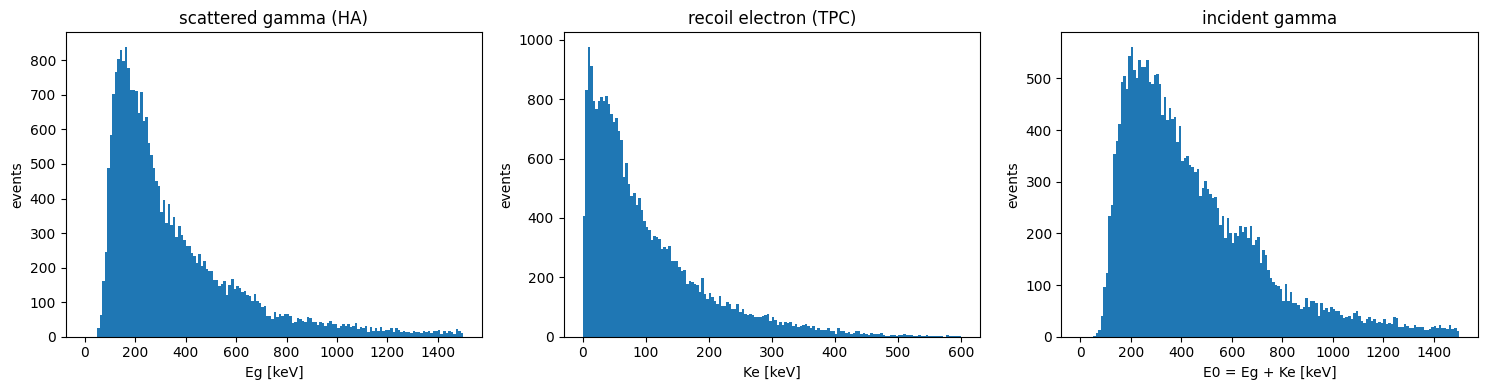

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(Eg, bins=150, range=(0, 1500)); ax[0].set_xlabel("Eg [keV]"); ax[0].set_title("scattered gamma (HA)")
ax[1].hist(Ke, bins=150, range=(0, 600));  ax[1].set_xlabel("Ke [keV]"); ax[1].set_title("recoil electron (TPC)")
ax[2].hist(E0, bins=150, range=(0, 1500)); ax[2].set_xlabel("E0 = Eg + Ke [keV]"); ax[2].set_title("incident gamma")
for x in ax: x.set_ylabel("events")
fig.tight_layout(); plt.show()

### 5b. 電子飛跡(`TOT_Skewness`)
TPC の飛跡から、散乱点 `Pe_TRA` と電子の進行方向 `Ve_TRA` を求めています。
z 座標はドリフト時間から計算し、ドリフト速度は `drift_velocity.dat` の表を
**イベント時刻ごとに**引いています(参照と同じ。イベント時刻は TPC 生データのヘッダにある
DAQ 開始からの経過時間カウンタ)。

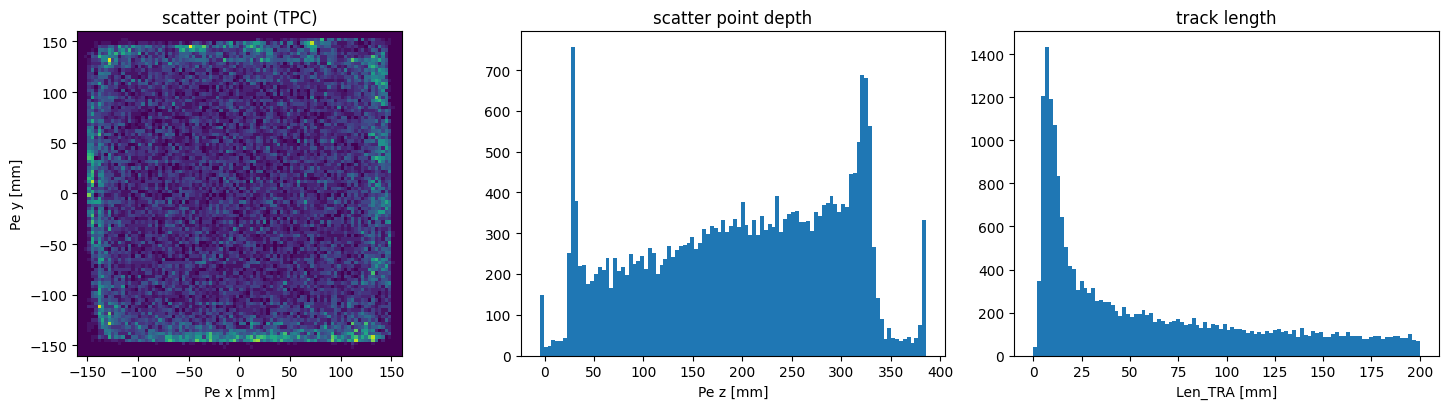

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
h = ax[0].hist2d(Pe[:, 0], Pe[:, 1], bins=96, range=[[-160, 160], [-160, 160]])
ax[0].set_xlabel("Pe x [mm]"); ax[0].set_ylabel("Pe y [mm]"); ax[0].set_title("scatter point (TPC)")
ax[0].set_aspect("equal")
ax[1].hist(Pe[:, 2], bins=100); ax[1].set_xlabel("Pe z [mm]"); ax[1].set_title("scatter point depth")
ax[2].hist(Len, bins=100, range=(0, 200)); ax[2].set_xlabel("Len_TRA [mm]"); ax[2].set_title("track length")
fig.tight_layout(); plt.show()

### 5c. イベント選択(`SetCrit`)

本番解析(`s2p_chk_std2_Erica_v2_1.cc` の `SetCrit`)と同じ条件で選びます。
「エネルギー範囲 → 飛跡が丸ごと検出器内 → ガス中で止まった電子らしい → 1 回のコンプトン散乱として矛盾しない」
の順に絞っていく選択です。

| 条件 | 内容 | 意味 |
|---|---|---|
| Eg | 0.15 MeV ≤ Eg ≤ 2.1 MeV | シンチの閾値付近のノイズ・低エネルギー背景と、ダイナミックレンジを超えるイベントを除く |
| criteria[0] 有効体積 | 飛跡の範囲 `Track_Min/Max` が x, y とも −148.6〜148.6 mm、z が 32〜327 mm | 飛跡**全体**が読み出し領域(±153.6 mm = 384 strip × 0.8 mm / 2)と GEM 面(z = 27 mm)・ドリフト上端から 5 mm 以上内側にある。壁や GEM からはみ出した飛跡は Ke を測り損ね、方向も怪しい。構造物由来の背景も減らす |
| criteria[1] dE/dx | `913.9·Ke² + 2.2 < Len < 1975.9·Ke^1.4 + 7`(Ke [MeV], Len [mm])かつ `Len < 270` | 電子の飛程はエネルギーでほぼ決まる(Range ∝ E^n)。長すぎる = 宇宙線ミューオンなど最小電離粒子や Ke の測り損ね、短すぎる = 陽子・α など dE/dx の大きい粒子や飛跡の取りこぼし。**ガス中で止まった電子**を選ぶ粒子識別 |
| criteria[2] Δcos α | −0.5 ≤ cos α_geo − cos α_kin ≤ 0.5 | 反跳電子と散乱ガンマ線のなす角を、飛跡から(幾何)とエネルギーから(運動学)の 2 通りで求めて比べる ETCC 固有のカット。電子の向きの誤判定、散乱点のずれ、偶然同時計数、多重散乱などを除く |

- `cos α_geo = ĝ · ê`(`ĝ = (Pg − Pe)/|Pg − Pe|`、`ê = Ve/|Ve|`)、`cos α_kin` は `Eg`, `Ke` だけから求めた値(`alpha_kin` 分岐 [deg])。
- `Len_TRA` は実際の道のりではなく、`Track_Min` と `Track_Max` を角とする箱の対角線の長さ。
- dE/dx の係数は、Sauli の飛程の式(`7.1·E^1.72` g/cm²、ガス Ar:CF4:iC4H10 = 95:3:2、2 気圧)を基に、
  実データの帯に合わせて上下に広げた経験的な値(`SetCrit` 内でコメントアウトされている版が Sauli の式そのもの)。

In [7]:
MC2 = 510.9989461  # keV (SMLib Compton_common::mass_e)

g = Pg - Pe
g_unit = g / np.linalg.norm(g, axis=1, keepdims=True)
e_unit = Ve / np.linalg.norm(Ve, axis=1, keepdims=True)
cos_geo = np.sum(g_unit * e_unit, axis=1)
dcos = cos_geo - np.cos(np.pi * alpha_kin / 180.)
Ke_MeV, Eg_MeV = Ke / 1000., Eg / 1000.

cut_eg  = (Eg_MeV >= 0.15) & (Eg_MeV <= 2.1)
cut_fid = ((-153.6 + 5. < TrkMin[:, 0]) & (TrkMax[:, 0] < -5. + 153.6)
         & (-153.6 + 5. < TrkMin[:, 1]) & (TrkMax[:, 1] < -5. + 153.6)
         & (  27.0 + 5. < TrkMin[:, 2]) & (TrkMax[:, 2] < -5. + 332.0))
with np.errstate(invalid="ignore"):
    cut_dedx = ((Len < 1975.9 * np.power(Ke_MeV, 1.4) + 7.)
              & (Len > 913.9 * np.power(Ke_MeV, 2.0) + 2.2)
              & (Len < 270.))
cut_dcos = (-0.5 <= dcos) & (dcos <= 0.5)

steps = [("err_flag == 0", np.ones(len(Eg), bool)),
         ("+ Eg 0.15-2.1 MeV", cut_eg),
         ("+ fiducial volume", cut_fid),
         ("+ dE/dx", cut_dedx),
         ("+ |dcos alpha| <= 0.5", cut_dcos)]
sel = np.ones(len(Eg), bool)
for name, c in steps:
    sel &= c
    print(f"{name:24s} {sel.sum():7d}")

err_flag == 0              26513
+ Eg 0.15-2.1 MeV          20932
+ fiducial volume          15080
+ dE/dx                     8940
+ |dcos alpha| <= 0.5       4874


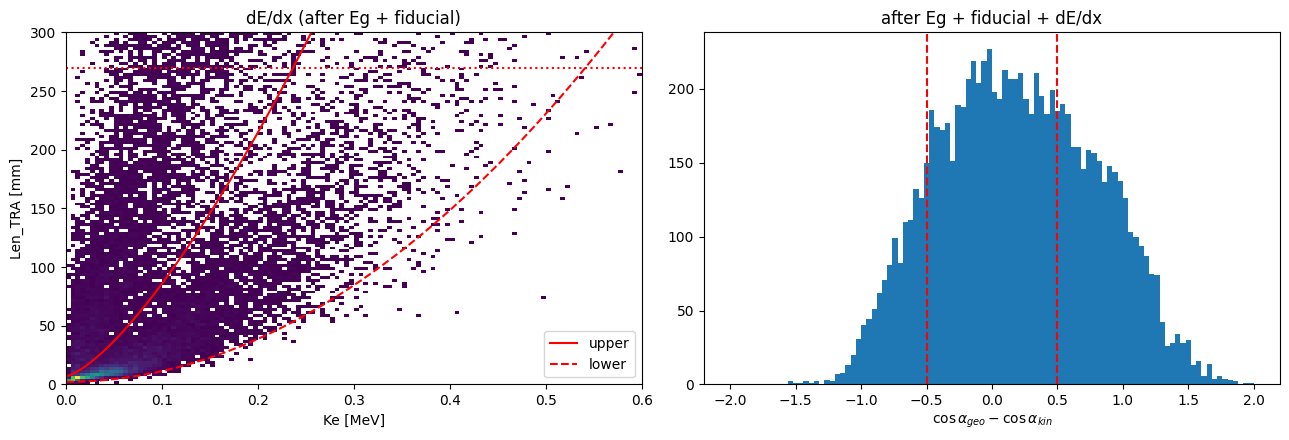

In [8]:
ke = np.linspace(0.001, 0.6, 300)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
base = cut_eg & cut_fid
ax[0].hist2d(Ke_MeV[base], Len[base], bins=[120, 120], range=[[0, 0.6], [0, 300]], cmin=1)
ax[0].plot(ke, 1975.9 * ke**1.4 + 7., "r-", label="upper")
ax[0].plot(ke, 913.9 * ke**2.0 + 2.2, "r--", label="lower")
ax[0].axhline(270, color="r", ls=":")
ax[0].set_xlabel("Ke [MeV]"); ax[0].set_ylabel("Len_TRA [mm]"); ax[0].set_title("dE/dx (after Eg + fiducial)")
ax[0].legend()
base2 = base & cut_dedx
ax[1].hist(dcos[base2], bins=100, range=(-2, 2))
ax[1].axvline(-0.5, color="r", ls="--"); ax[1].axvline(0.5, color="r", ls="--")
ax[1].set_xlabel(r"$\cos\alpha_{geo} - \cos\alpha_{kin}$"); ax[1].set_title("after Eg + fiducial + dE/dx")
fig.tight_layout(); plt.show()

## 6. バックプロジェクション像

ETCC は散乱ガンマ線の向きだけでなく反跳電子の向きも測るので、運動量保存から
入射ガンマ線の方向をイベントごとに 1 本の直線として決められます
(参照 `Compton_common::recon_vector` と同じ式):

$$\hat r = \frac{E_g\,\hat g + K_e\sqrt{1 + 2m_ec^2/K_e}\;\hat e}{\left|\,\cdots\right|}$$

$\hat r$ は**線源から検出器へ向かう**向きなので、散乱点 `Pe` から線源の平面
(`z = -1626 mm`, 参照の `Source_Position_Z`)まで戻る距離は
`d = -(Pe_z - z_src) / r_z` です(参照 `Reconstruct` の `backprojection` と同じ。d は負になります)。
5c の選択をすべて通ったイベントで描きます。

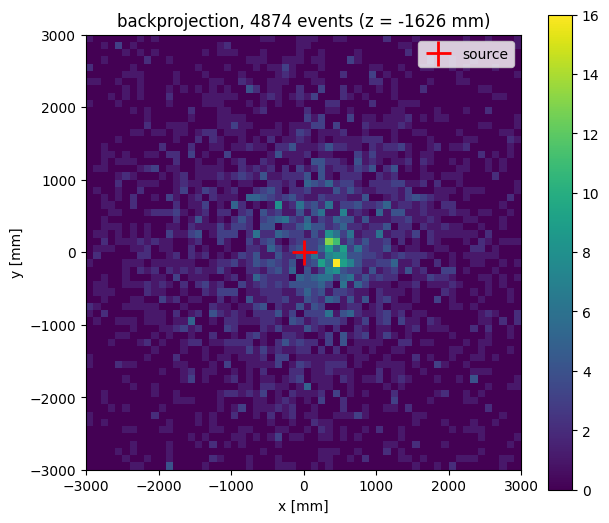

median of backprojected points: x = 143 mm, y = 45 mm


In [9]:
SRC = np.array([0.0, 0.0, -1626.0])   # mm

Kp = np.where(Ke > 0, Ke, np.nan)
rcs = Eg[:, None] * g_unit + (Kp * np.sqrt(1 + 2 * MC2 / Kp))[:, None] * e_unit
r_unit = rcs / np.linalg.norm(rcs, axis=1, keepdims=True)
d = -(Pe[:, 2] - SRC[2]) / r_unit[:, 2]
bp = Pe + d[:, None] * r_unit

R = 3000
fig, ax = plt.subplots(figsize=(6.5, 5.5))
h = ax.hist2d(bp[sel, 0], bp[sel, 1], bins=60, range=[[-R, R], [-R, R]], cmap="viridis")
ax.plot(SRC[0], SRC[1], "r+", ms=18, mew=2, label="source")
ax.set_xlabel("x [mm]"); ax.set_ylabel("y [mm]"); ax.set_aspect("equal")
ax.set_title(f"backprojection, {sel.sum()} events (z = {SRC[2]:.0f} mm)"); ax.legend()
fig.colorbar(h[3], ax=ax)
fig.tight_layout(); plt.show()

inr = sel & (np.abs(bp[:, 0]) < R) & (np.abs(bp[:, 1]) < R)
print("median of backprojected points: x = %.0f mm, y = %.0f mm"
      % (np.median(bp[inr, 0]), np.median(bp[inr, 1])))

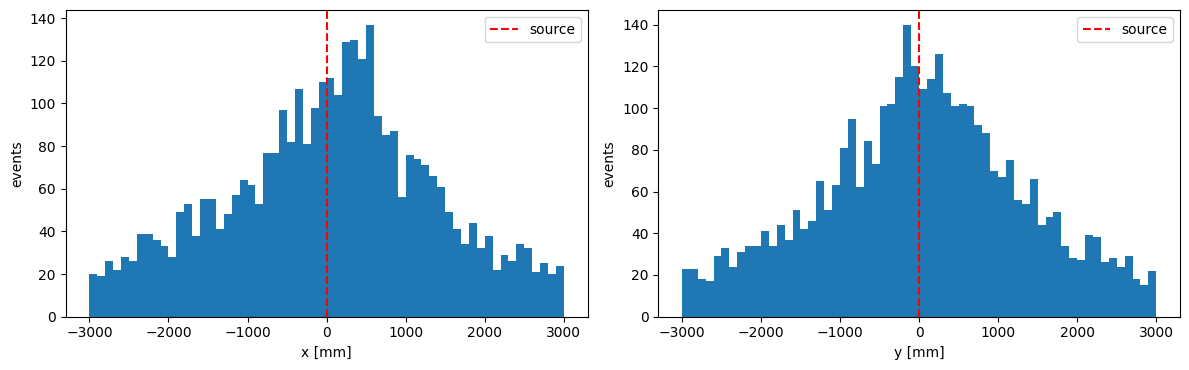

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for k, lab in enumerate("xy"):
    ax[k].hist(bp[sel, k], bins=60, range=(-R, R))
    ax[k].axvline(SRC[k], color="r", ls="--", label="source")
    ax[k].set_xlabel(f"{lab} [mm]"); ax[k].set_ylabel("events"); ax[k].legend()
fig.tight_layout(); plt.show()

## 7. 参照(SMILE_tool_box)との一致確認

参照ファイルがあれば、同じ行どうしで主要な分岐を比べます(`sevt_id` = 参照の `SEvt_ID` で 1:1 に対応)。

In [11]:
REF = "/home/onoda/hikaru3_analysis2/sm2+_cal_rootdata/20190701_Per03/haboc_tmp_0.root"
if not os.path.exists(REF):
    print("reference file not found:", REF)
else:
    fr = ROOT.TFile.Open(REF); ref = fr.Get("Reconstruct/s2t")
    checks = {"err_flag": 0, "Eg": 0, "Ke(=Ee)": 0, "Pg": 0, "Pe_TRA": 0, "Len_TRA": 0}
    n = tree.GetEntries()
    for i in range(n):
        tree.GetEntry(i); ref.GetEntry(i)
        assert tree.sevt_id == ref.SEvt_ID
        checks["err_flag"] += tree.err_flag == ref.err_flag
        checks["Eg"]       += tree.Eg == ref.Eg[0]
        checks["Ke(=Ee)"]  += tree.Ke == ref.Ee
        checks["Pg"]       += all(tree.Pg[k] == ref.Pg[k] for k in range(3))
        checks["Pe_TRA"]   += all(tree.Pe_TRA[k] == ref.Pe_TRA[k] for k in range(6))
        checks["Len_TRA"]  += tree.Len_TRA == ref.Len_TRA
    for k, v in checks.items():
        print(f"{k:10s} bit-identical: {v} / {n}")

err_flag   bit-identical: 49998 / 50000
Eg         bit-identical: 49994 / 50000
Ke(=Ee)    bit-identical: 49994 / 50000
Pg         bit-identical: 49994 / 50000
Pe_TRA     bit-identical: 160 / 50000
Len_TRA    bit-identical: 23525 / 50000


ビット単位で一致しない可能性があるのは次の分岐だけで、いずれも参照を作った環境との差です。

- `phi_kin` / `psi_kin` / `alpha_kin` / `skewness`: 数学ライブラリ(`acos`, `pow`)の最下位ビットの差
- `Ve_TRA`: 参照は ROOT 6.14 の TMinuit でフィットしており、ROOT のバージョン差で収束値が
  相対 1e-12 程度ずれる(ほぼ垂直な飛跡では傾きの微小差が拡大されることがある)

## 次のステップ

- `N_EVENTS = -1` にすれば全 815630 イベントを処理できます(約 1 時間)。
- `DATA_DIR` を他の期間(例: `Per03_ETCC`)に差し替えれば同じチェーンで解析できます。
  パラメータはその期間の `HabocStatus.scl` に合わせてください。
- モジュール構成の設計は Notion の「EricaNext 開発ドキュメント」を参照してください。